-------
## Projekt 1 - Wstęp do Uczenia Maszynowego 2026Z

## Kod KM1

-------


**Imię i Nazwisko: Błażej Klepacki** 

**Prowadzący:** AK

**Kierunek:** MAD

**Numer albumu: 331389**

------

### *Import pakietów*

-------

In [1]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
import sklearn

from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, average_precision_score
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.tree import DecisionTreeClassifier

from sklearn.model_selection import GridSearchCV

In [2]:
X_test = pd.read_csv("X_test.csv")
X_train = pd.read_csv("X_train.csv")
y_train = pd.read_csv("y_train.csv")


### *1. Eksploracyjna analiza danych*
-------

X_train: (6400, 23), y_train: (6400,), X_test: (1600, 23)
duplikaty w X_train: 0
default.payment.next.month
0    5019
1    1381
Name: count, dtype: int64
default.payment.next.month
0    0.784
1    0.216
Name: proportion, dtype: float64
<class 'pandas.DataFrame'>
RangeIndex: 6400 entries, 0 to 6399
Data columns (total 23 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   LIMIT_BAL  6400 non-null   float64
 1   SEX        6400 non-null   int64  
 2   EDUCATION  6400 non-null   int64  
 3   MARRIAGE   6400 non-null   int64  
 4   AGE        6400 non-null   int64  
 5   PAY_0      6400 non-null   int64  
 6   PAY_2      6400 non-null   int64  
 7   PAY_3      6400 non-null   int64  
 8   PAY_4      6400 non-null   int64  
 9   PAY_5      5764 non-null   float64
 10  PAY_6      6400 non-null   int64  
 11  BILL_AMT1  6400 non-null   float64
 12  BILL_AMT2  6400 non-null   float64
 13  BILL_AMT3  6400 non-null   float64
 14  BILL_AMT4  6400 non-nul

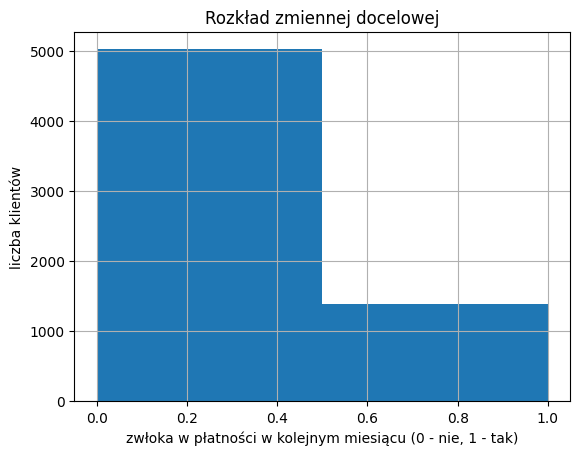

In [3]:
# wymiary, typy, duplikaty i rozkład zmiennej docelowej (y_train zamieniam z dataframe na series)
y_train = y_train.squeeze()

print(f"X_train: {X_train.shape}, y_train: {y_train.shape}, X_test: {X_test.shape}")
print(f"duplikaty w X_train: {X_train.duplicated().sum()}")
print(y_train.value_counts())
print(y_train.value_counts(normalize=True).round(3))

X_train.info()

y_train.hist(bins=2)
plt.title("Rozkład zmiennej docelowej")
plt.xlabel("zwłoka w płatności w kolejnym miesiącu (0 - nie, 1 - tak)")
plt.ylabel("liczba klientów")
plt.show()

In [4]:
# statystyki opisowe wszystkich zmiennych (transponowane dla czytelności)
X_train.describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
LIMIT_BAL,6400.0,167058.3,130788.6,-157.5,54027.8,138508.7,236847.7,783258.4
SEX,6400.0,1.6,0.5,1.0,1.0,2.0,2.0,2.0
EDUCATION,6400.0,1.8,0.8,0.0,1.0,2.0,2.0,6.0
MARRIAGE,6400.0,1.6,0.5,0.0,1.0,2.0,2.0,3.0
AGE,6400.0,34.8,9.1,19.0,28.0,33.0,41.0,73.0
PAY_0,6400.0,-0.0,1.1,-2.0,-1.0,0.0,0.0,8.0
PAY_2,6400.0,-0.1,1.2,-2.0,-1.0,0.0,0.0,7.0
PAY_3,6400.0,-0.2,1.2,-3.0,-1.0,0.0,0.0,7.0
PAY_4,6400.0,-0.2,1.2,-2.0,-1.0,0.0,0.0,7.0
PAY_5,5764.0,-0.3,1.1,-2.0,-1.0,0.0,0.0,7.0


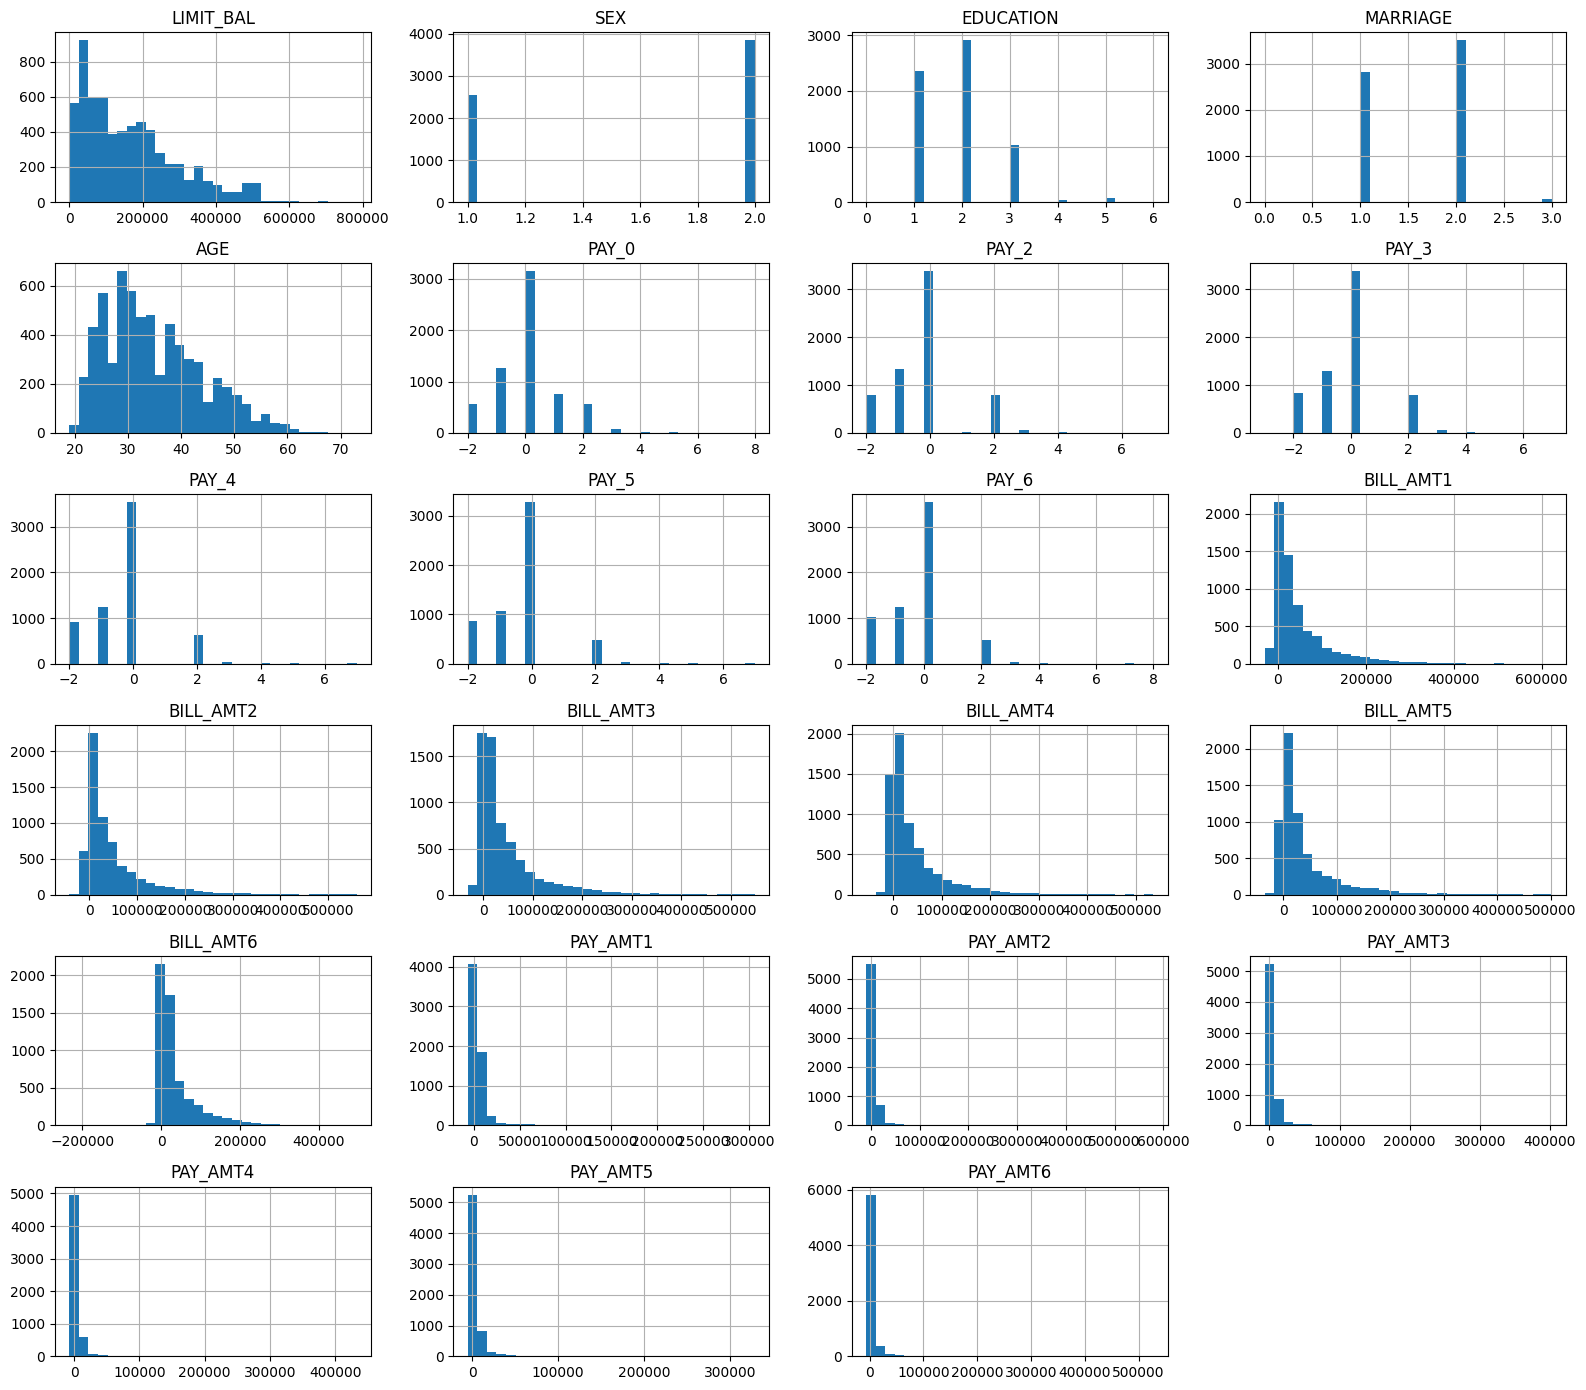

In [5]:
# histogramy wszystkich zmiennych
X_train.hist(bins=30, figsize=(16, 14), layout=(6, 4), sharex=False, sharey=False)
plt.tight_layout()
plt.show()

In [6]:
# liczność kategorii w zmiennych kategorycznych (na histogramie słabo to widać)
for c in ["SEX", "EDUCATION", "MARRIAGE"]:
    print(c, X_train[c].value_counts().sort_index().to_dict())

SEX {1: 2555, 2: 3845}
EDUCATION {0: 4, 1: 2352, 2: 2910, 3: 1030, 4: 29, 5: 69, 6: 6}
MARRIAGE {0: 11, 1: 2824, 2: 3501, 3: 64}


### *1.1 Braki danych*
-------

In [7]:
# liczba i procent braków w train i test (tylko kolumny, w których coś brakuje)
braki = pd.DataFrame({
    "train": X_train.isna().sum(),
    "train_%": (X_train.isna().mean() * 100).round(1),
    "test": X_test.isna().sum(),
    "test_%": (X_test.isna().mean() * 100).round(1),
})
print(braki[braki["train"] > 0])
print("wiersze z jakimś brakiem:", X_train.isna().any(axis=1).sum(), "z", len(X_train))

           train  train_%  test  test_%
PAY_5        636      9.9   164    10.2
BILL_AMT6    653     10.2   147     9.2
PAY_AMT4     635      9.9   165    10.3
wiersze z jakimś brakiem: 1743 z 6400


In [8]:
# sprawdzam, czy braki są ze sobą skorelowane i czy zależą od zmiennej docelowej
kol_braki = ["PAY_5", "BILL_AMT6", "PAY_AMT4"]

print(X_train[kol_braki].isna().corr().round(2))

for c in kol_braki:
    czy_brak = X_train[c].isna()
    print(f"{c} | zwłoka przy braku: {y_train[czy_brak].mean():.3f} | bez braku: {y_train[~czy_brak].mean():.3f}")

           PAY_5  BILL_AMT6  PAY_AMT4
PAY_5       1.00       -0.0     -0.01
BILL_AMT6  -0.00        1.0      0.00
PAY_AMT4   -0.01        0.0      1.00
PAY_5 | zwłoka przy braku: 0.230 | bez braku: 0.214
BILL_AMT6 | zwłoka przy braku: 0.242 | bez braku: 0.213
PAY_AMT4 | zwłoka przy braku: 0.224 | bez braku: 0.215


### *1.2 Wartości odstające*
-------

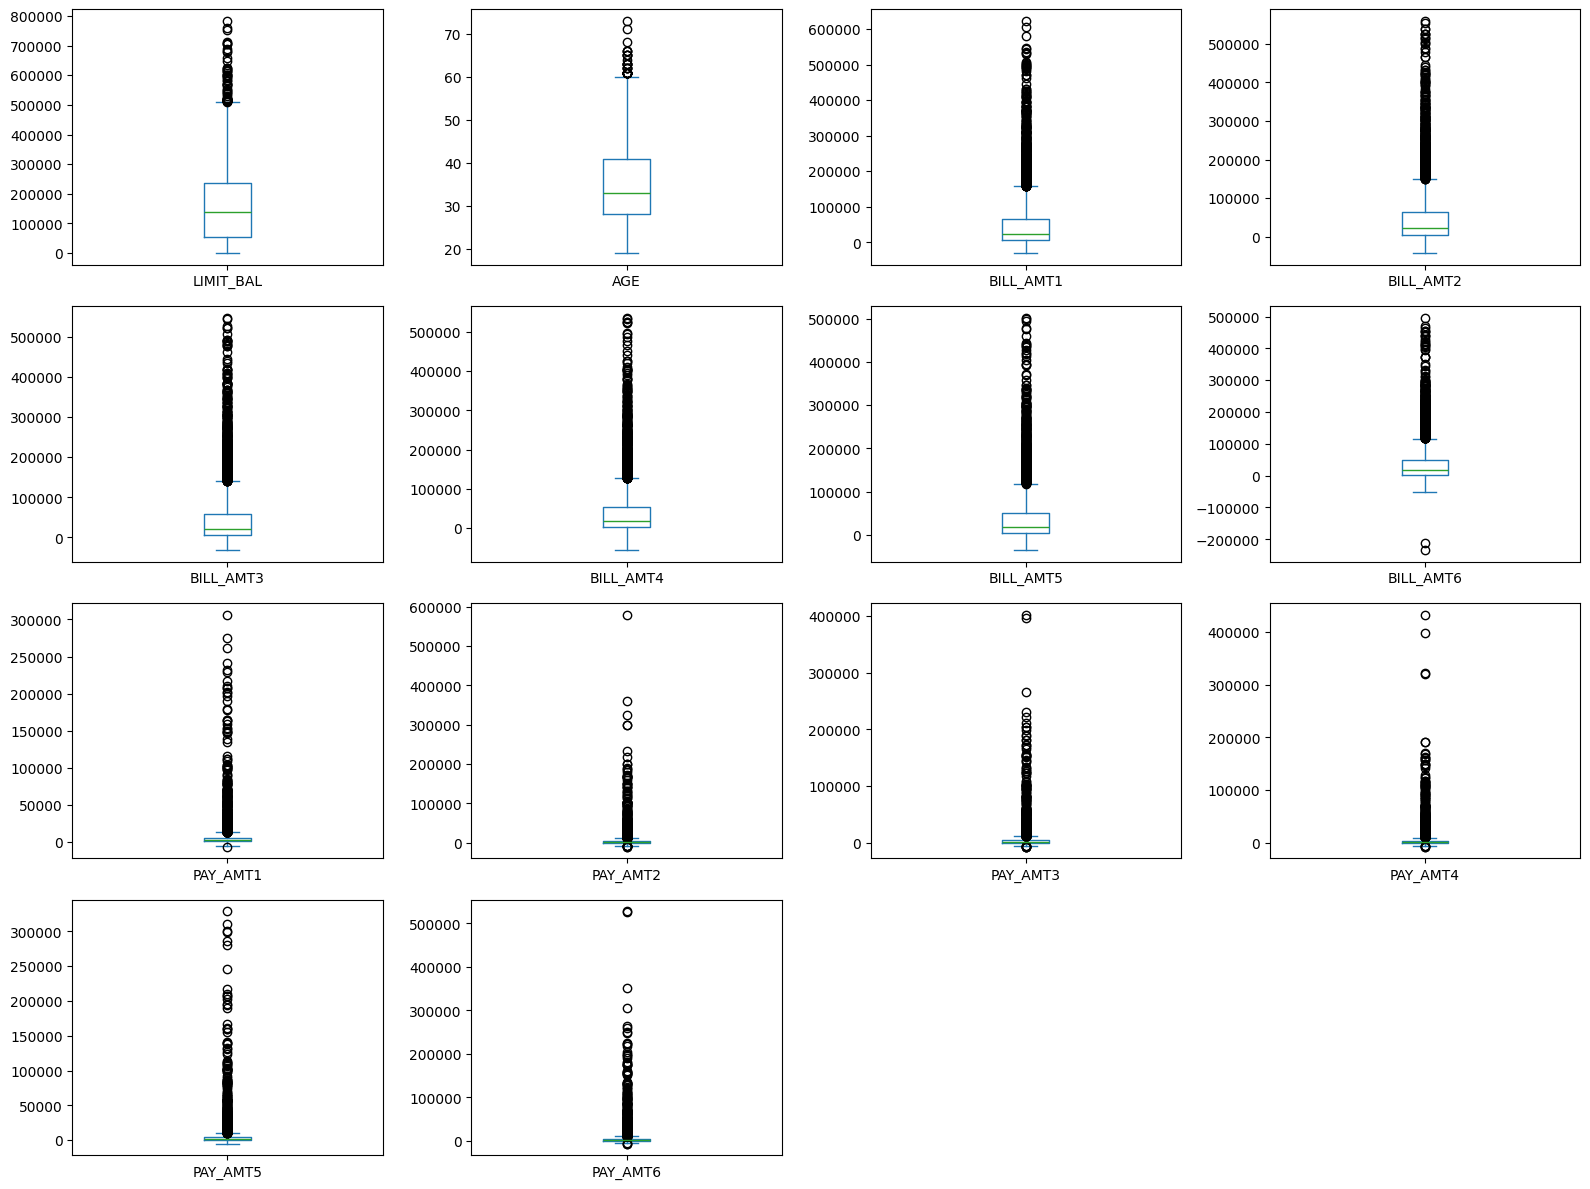

In [9]:
# boxploty zmiennych ciągłych, żeby zobaczyć outliery
ciagle = ["LIMIT_BAL", "AGE"] + [f"BILL_AMT{i}" for i in range(1, 7)] + [f"PAY_AMT{i}" for i in range(1, 7)]

X_train[ciagle].plot(kind="box", subplots=True, layout=(4, 4), figsize=(16, 12),
                     sharex=False, sharey=False)
plt.tight_layout()
plt.show()

In [10]:
# ile obserwacji wypada poza wąsy boxplota (reguła 1.5 * IQR)
Q1 = X_train[ciagle].quantile(0.25)
Q3 = X_train[ciagle].quantile(0.75)
IQR = Q3 - Q1
poza = (X_train[ciagle] < Q1 - 1.5 * IQR) | (X_train[ciagle] > Q3 + 1.5 * IQR)

pd.DataFrame({"liczba": poza.sum(), "%": (poza.mean() * 100).round(1)})

,liczba,%
LIMIT_BAL,63,1.0
AGE,34,0.5
BILL_AMT1,517,8.1
BILL_AMT2,547,8.5
BILL_AMT3,575,9.0
BILL_AMT4,590,9.2
BILL_AMT5,593,9.3
BILL_AMT6,541,8.5
PAY_AMT1,563,8.8
PAY_AMT2,569,8.9


In [11]:
# podejrzane wartości ujemne, bo limit i wpłaty raczej nie powinny być ujemne
print("LIMIT_BAL < 0:", (X_train["LIMIT_BAL"] < 0).sum())
print("PAY_AMT < 0:")
print((X_train.filter(like="PAY_AMT") < 0).sum())
print("BILL_AMT < 0:")
print((X_train.filter(like="BILL_AMT") < 0).sum())
print("wiersze z min. jedną ujemną wpłatą (%):",
      round((X_train.filter(like="PAY_AMT") < 0).any(axis=1).mean() * 100, 1))

LIMIT_BAL < 0: 1
PAY_AMT < 0:
PAY_AMT1     920
PAY_AMT2    1132
PAY_AMT3    1085
PAY_AMT4    1093
PAY_AMT5    1155
PAY_AMT6    1219
dtype: int64
BILL_AMT < 0:
BILL_AMT1    833
BILL_AMT2    873
BILL_AMT3    903
BILL_AMT4    927
BILL_AMT5    936
BILL_AMT6    890
dtype: int64
wiersze z min. jedną ujemną wpłatą (%): 56.9


### *1.3 Relacje i istotność zmiennych*
-------

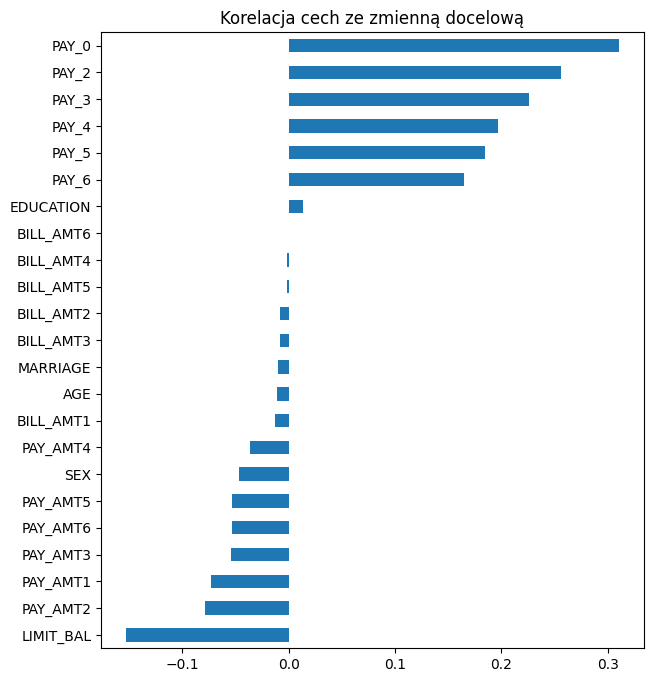

LIMIT_BAL   -0.153
PAY_AMT2    -0.078
PAY_AMT1    -0.073
PAY_AMT3    -0.054
PAY_AMT6    -0.054
PAY_AMT5    -0.053
SEX         -0.047
PAY_AMT4    -0.037
BILL_AMT1   -0.013
AGE         -0.011
MARRIAGE    -0.010
BILL_AMT3   -0.008
BILL_AMT2   -0.008
BILL_AMT5   -0.002
BILL_AMT4   -0.001
BILL_AMT6    0.000
EDUCATION    0.014
PAY_6        0.165
PAY_5        0.185
PAY_4        0.197
PAY_3        0.226
PAY_2        0.256
PAY_0        0.311
dtype: float64


In [12]:
# korelacja każdej cechy ze zmienną docelową
kor_y = X_train.corrwith(y_train).sort_values()
kor_y.plot(kind="barh", figsize=(7, 8))
plt.title("Korelacja cech ze zmienną docelową")
plt.show()
print(kor_y.round(3))

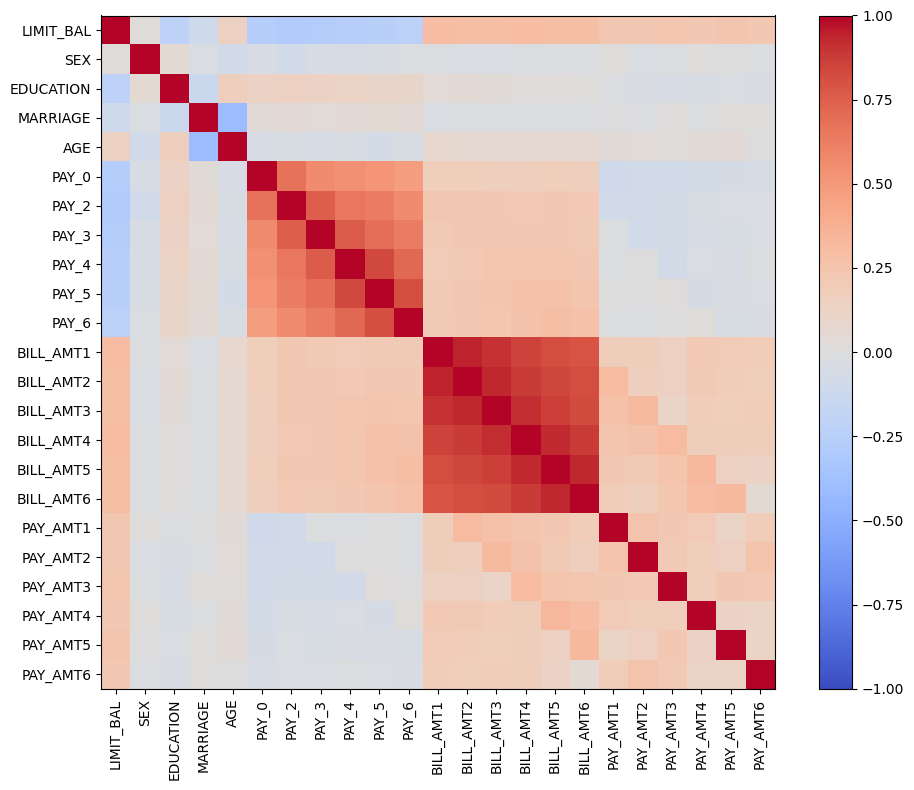

           BILL_AMT1  BILL_AMT2  BILL_AMT3  BILL_AMT4  BILL_AMT5  BILL_AMT6
BILL_AMT1       1.00       0.94       0.91       0.85       0.81       0.79
BILL_AMT2       0.94       1.00       0.94       0.88       0.84       0.82
BILL_AMT3       0.91       0.94       1.00       0.91       0.86       0.83
BILL_AMT4       0.85       0.88       0.91       1.00       0.92       0.88
BILL_AMT5       0.81       0.84       0.86       0.92       1.00       0.93
BILL_AMT6       0.79       0.82       0.83       0.88       0.93       1.00


In [13]:
# macierz korelacji między cechami i osobno korelacje kolumn BILL_AMT
fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(X_train.corr(), cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(X_train.shape[1]))
ax.set_yticks(range(X_train.shape[1]))
ax.set_xticklabels(X_train.columns, rotation=90)
ax.set_yticklabels(X_train.columns)
plt.colorbar(im)
plt.tight_layout()
plt.show()

print(X_train.filter(like="BILL_AMT").corr().round(2))

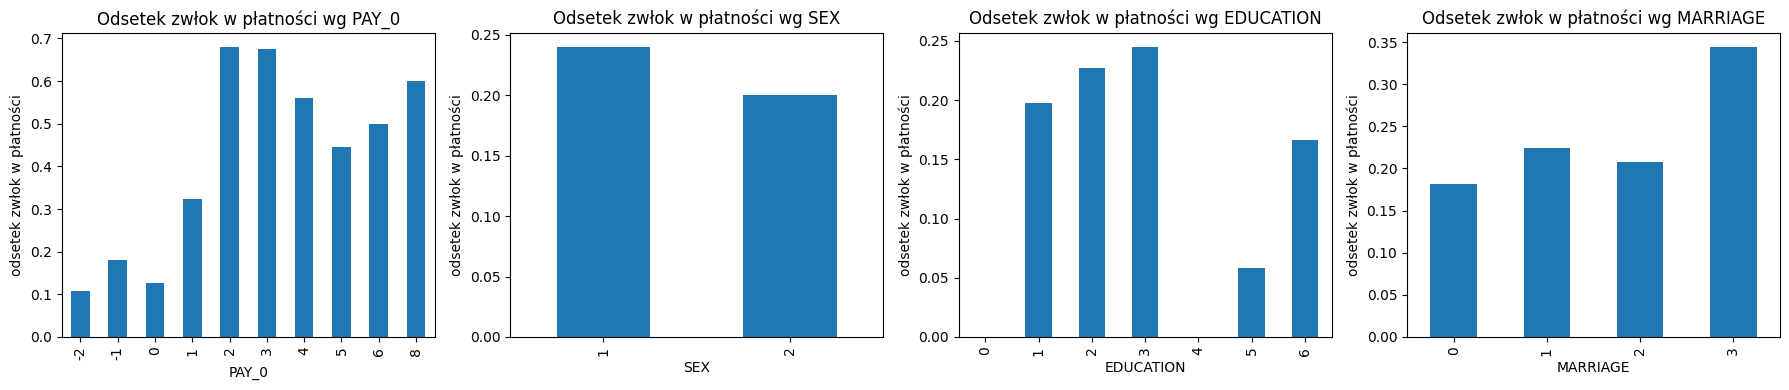

In [14]:
# odsetek zwłok w płatności w grupach (PAY_0 i zmienne kategoryczne)
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, c in zip(axes, ["PAY_0", "SEX", "EDUCATION", "MARRIAGE"]):
    y_train.groupby(X_train[c]).mean().plot(kind="bar", ax=ax)
    ax.set_title(f"Odsetek zwłok w płatności wg {c}")
    ax.set_ylabel("odsetek zwłok w płatności")
plt.tight_layout()
plt.show()

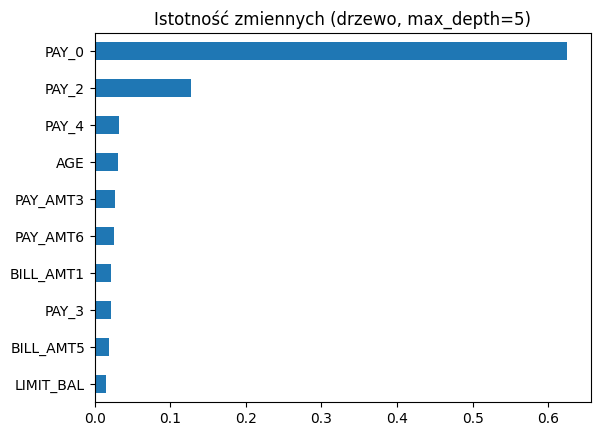

PAY_0        0.625
PAY_2        0.127
PAY_4        0.032
AGE          0.031
PAY_AMT3     0.027
PAY_AMT6     0.026
BILL_AMT1    0.021
PAY_3        0.021
BILL_AMT5    0.019
LIMIT_BAL    0.016
dtype: float64


In [15]:
# płytkie drzewo tylko do oceny istotności zmiennych (drzewo radzi sobie z nan, więc nic nie uzupełniam)
tree_eda = DecisionTreeClassifier(max_depth=5, random_state=123)
tree_eda.fit(X_train, y_train)

imp = pd.Series(tree_eda.feature_importances_, index=X_train.columns).sort_values(ascending=False)
imp.head(10).sort_values().plot(kind="barh")
plt.title("Istotność zmiennych (drzewo, max_depth=5)")
plt.show()
print(imp.head(10).round(3))

### *2. Metryka ewaluacji i podział danych*
-------

In [16]:
# naiwny klasyfikator (zawsze klasa większościowa) jako punkt odniesienia dla metryk

naiwny = DummyClassifier(strategy="most_frequent")
naiwny.fit(X_train, y_train)
y_naiwny = naiwny.predict(X_train)
p_naiwny = naiwny.predict_proba(X_train)[:, 1]

print(f"accuracy: {accuracy_score(y_train, y_naiwny):.3f}")
print(f"F1: {f1_score(y_train, y_naiwny):.3f}")
print(f"ROC AUC: {roc_auc_score(y_train, p_naiwny):.3f}")
print(f"average precision: {average_precision_score(y_train, p_naiwny):.3f}")

accuracy: 0.784
F1: 0.000
ROC AUC: 0.500
average precision: 0.216


**Wybór metryki**

Zadanie to klasyfikacja binarna, a wynikiem końcowym ma być wektor prawdopodobieństw klasy 1, więc potrzebujemy metryki, która ocenia prawdopodobieństwa, a nie same etykiety. Jako główną metrykę wybieram **ROC AUC**, bo nie zależy od progu odcięcia i mówi, jak dobrze model układa klientów od najmniej do najbardziej ryzykownych. Klasy są niezbalansowane (21,6% klasy 1), więc accuracy jest mylące: klasyfikator, który zawsze zgaduje klasę 0, ma accuracy 0,784, ale AUC 0,5 i F1 równe 0. Pomocniczo liczę **average precision**, bo jest czulsza, gdy klasa pozytywna jest rzadka, a losowy klasyfikator ma AP równe udziałowi klasy 1 (0,216). Accuracy podaję tylko dla porównania.

### *2.1 Strategia podziału danych*
-------

In [17]:
# podział 80/20 ze stratyfikacją po y (hold-out to mój zbiór testowy, bo X_test nie ma etykiet)

X_tr, X_ho, y_tr, y_ho = train_test_split(
    X_train, y_train, test_size=0.2, stratify=y_train, random_state=123
)
print(f"zbiór uczący: {X_tr.shape}, zbiór hold-out: {X_ho.shape}")
print(f"udział klasy 1: całość {y_train.mean():.3f}, uczący {y_tr.mean():.3f}, hold-out {y_ho.mean():.3f}")

zbiór uczący: (5120, 23), zbiór hold-out: (1280, 23)
udział klasy 1: całość 0.216, uczący 0.216, hold-out 0.216


In [18]:
# 5-krotna stratyfikowana CV i kontrola rozmiarów foldów oraz udziału klasy 1 w każdym z nich

cv_5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=123)

for i, (idx_fit, idx_val) in enumerate(cv_5.split(X_tr, y_tr), start=1):
    print(f"fold {i}: uczący {len(idx_fit)}, walidacyjny {len(idx_val)}, udział klasy 1 w walidacyjnym {y_tr.iloc[idx_val].mean():.3f}")

fold 1: uczący 4096, walidacyjny 1024, udział klasy 1 w walidacyjnym 0.216
fold 2: uczący 4096, walidacyjny 1024, udział klasy 1 w walidacyjnym 0.216
fold 3: uczący 4096, walidacyjny 1024, udział klasy 1 w walidacyjnym 0.216
fold 4: uczący 4096, walidacyjny 1024, udział klasy 1 w walidacyjnym 0.216
fold 5: uczący 4096, walidacyjny 1024, udział klasy 1 w walidacyjnym 0.216


In [19]:
# CV domyślnego drzewa, wynik będzie punktem odniesienia dla tuningu

tree_base = DecisionTreeClassifier(random_state=123)
wyniki = cross_validate(tree_base, X_tr, y_tr, cv=cv_5,
                        scoring=["accuracy", "roc_auc", "average_precision"])

for m in ["accuracy", "roc_auc", "average_precision"]:
    s = wyniki[f"test_{m}"]
    print(f"{m}: {s.mean():.3f} +/- {s.std():.3f}")

accuracy: 0.733 +/- 0.009
roc_auc: 0.614 +/- 0.018
average_precision: 0.286 +/- 0.014


**Strategia podziału.**

Zbiór `X_test` nie ma etykiet, więc nie da się na nim niczego ocenić. Dlatego z `X_train` wydzielam 20% obserwacji jako zbiór hold-out (1280 obserwacji), stratyfikowany względem `y`, żeby udział klasy 1 był wszędzie taki sam (21,6%). Hold-out nie służy do doboru hiperparametrów ani modelu, użyję go tylko do końcowej oceny wybranego modelu. Eksploracyjna analiza była robiona na całym `X_train`, ale nie służyła do wyboru modelu ani hiperparametrów. Na pozostałych 80% (5120 obserwacji) dobieram hiperparametry za pomocą 5-krotnej stratyfikowanej walidacji krzyżowej. Wybrałem CV zamiast jednego podziału walidacyjnego, bo pojedynczy podział daje niestabilne wyniki (zauważone na lab 2), a stratyfikację dodałem ze względu na niezbalansowanie klas. Wszystkie `random_state` są ustawione na 123, więc wyniki się powtarzają.

### *3. Optymalizacja hiperparametrów modelu drzewa*
-------

**Wybór hiperparametrów.**

Drzewo z domyślnymi parametrami się przeucza (ROC AUC na zbiorze uczącym 1,0, a w CV tylko 0,61), więc wybrałem trzy hiperparametry, które ograniczają jego złożoność:
- `max_depth` - maksymalna głębokość drzewa,
- `min_samples_leaf` - minimalna liczba obserwacji w liściu,
- `ccp_alpha` - kara za złożoność w przycinaniu drzewa (cost-complexity pruning z lab 3).

Najpierw sprawdzam każdy z nich osobno (pozostałe domyślne), żeby zobaczyć, w jakim zakresie metryka się zmienia. Na tej podstawie ustalam siatkę: 7 wartości `max_depth` x 8 wartości `min_samples_leaf` x 6 wartości `ccp_alpha` = 336 kombinacji, każda oceniana 5-krotną stratyfikowaną CV na zbiorze uczącym. Wartości są gęściej tam, gdzie krzywe osobne mają maksimum. Wybieram według ROC AUC z CV, a average precision liczę pomocniczo.

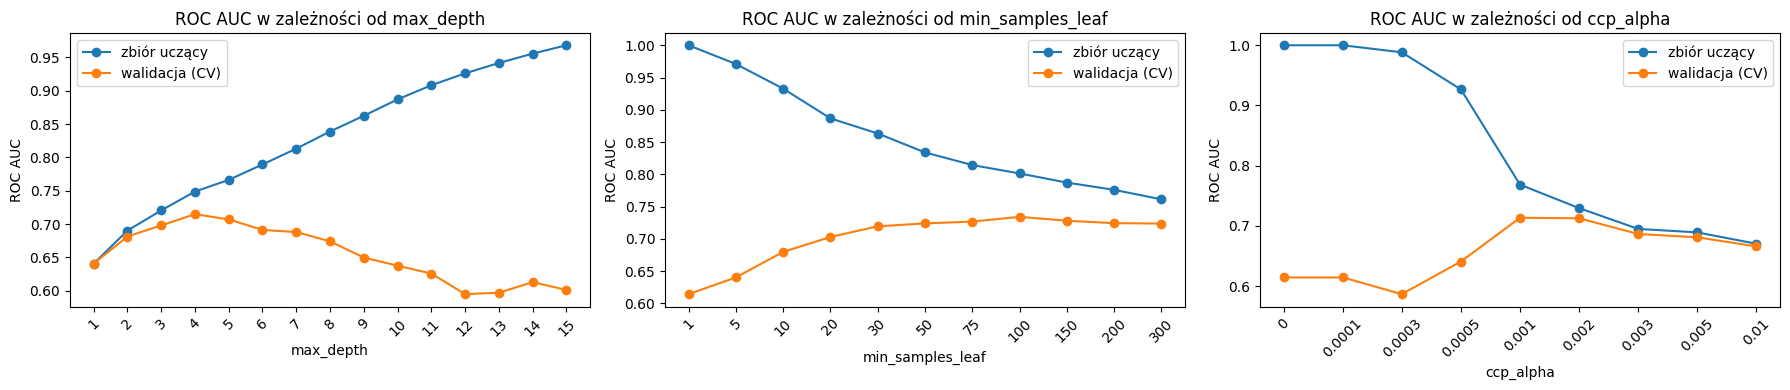

In [20]:
# wpływ każdego hiperparametru osobno (reszta domyślna): ROC AUC na zbiorze uczącym i w CV

zakresy = {
    "max_depth": list(range(1, 16)),
    "min_samples_leaf": [1, 5, 10, 20, 30, 50, 75, 100, 150, 200, 300],
    "ccp_alpha": [0, 1e-4, 3e-4, 5e-4, 1e-3, 2e-3, 3e-3, 5e-3, 1e-2],
}

fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, (nazwa, wartosci) in zip(axes, zakresy.items()):
    auc_uczacy, auc_cv = [], []
    for v in wartosci:
        model = DecisionTreeClassifier(random_state=123, **{nazwa: v})
        w = cross_validate(model, X_tr, y_tr, cv=cv_5, scoring="roc_auc", return_train_score=True)
        auc_uczacy.append(w["train_score"].mean())
        auc_cv.append(w["test_score"].mean())
    x = range(len(wartosci))
    ax.plot(x, auc_uczacy, marker="o", label="zbiór uczący")
    ax.plot(x, auc_cv, marker="o", label="walidacja (CV)")
    ax.set_xticks(x)
    ax.set_xticklabels(wartosci, rotation=45)
    ax.set_xlabel(nazwa)
    ax.set_ylabel("ROC AUC")
    ax.set_title(f"ROC AUC w zależności od {nazwa}")
    ax.legend()
plt.tight_layout()
plt.show()

In [21]:
# siatka trzech hiperparametrów, każda kombinacja oceniana 5-krotną CV, wybór po ROC AUC

siatka = {
    "max_depth": [3, 4, 5, 6, 8, 10, None],
    "min_samples_leaf": [1, 10, 30, 50, 75, 100, 150, 200],
    "ccp_alpha": [0, 1e-4, 3e-4, 5e-4, 1e-3, 2e-3],
}

gs = GridSearchCV(DecisionTreeClassifier(random_state=123), siatka, cv=cv_5,
                  scoring={"roc_auc": "roc_auc", "average_precision": "average_precision"},
                  refit="roc_auc", n_jobs=-1)
gs.fit(X_tr, y_tr)

print(f"liczba kombinacji: {len(gs.cv_results_['params'])}")
print(f"najlepsze parametry: {gs.best_params_}")
print(f"najlepszy CV ROC AUC: {gs.best_score_:.3f}")

liczba kombinacji: 336
najlepsze parametry: {'ccp_alpha': 0.0003, 'max_depth': 8, 'min_samples_leaf': 75}
najlepszy CV ROC AUC: 0.736


    param_max_depth  param_min_samples_leaf  param_ccp_alpha  mean_test_roc_auc  std_test_roc_auc  mean_test_average_precision
148               8                      75           0.0003             0.7362            0.0127                       0.4902
204               8                      75           0.0005             0.7359            0.0120                       0.4885
140               6                      75           0.0003             0.7355            0.0091                       0.4835
149               8                     100           0.0003             0.7344            0.0153                       0.4849
84                6                      75           0.0001             0.7343            0.0097                       0.4832
28                6                      75           0.0000             0.7343            0.0097                       0.4832
53             None                     100           0.0000             0.7342            0.0174              

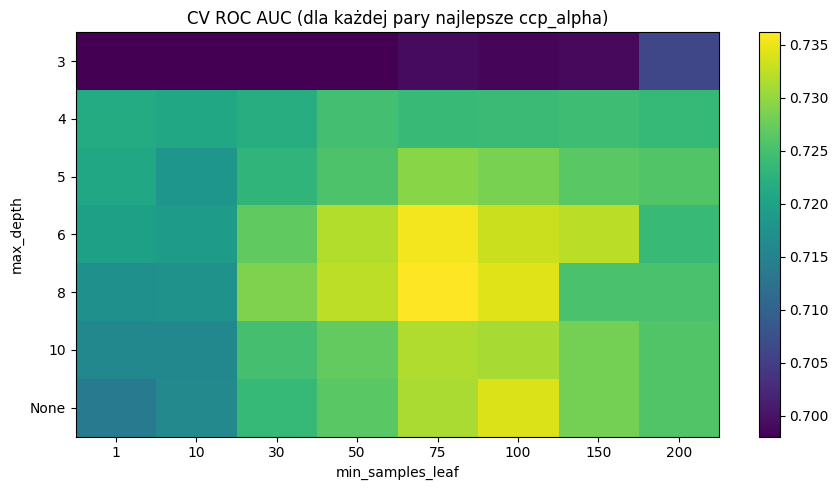

In [22]:
# 10 najlepszych kombinacji z siatki
wyniki_gs = pd.DataFrame(gs.cv_results_)
kolumny = ["param_max_depth", "param_min_samples_leaf", "param_ccp_alpha",
           "mean_test_roc_auc", "std_test_roc_auc", "mean_test_average_precision"]
print(wyniki_gs.sort_values("mean_test_roc_auc", ascending=False)[kolumny].head(10).round(4).to_string())

# najlepszy wynik CV dla każdej wartości hiperparametru (po pozostałych)
for p in ["param_max_depth", "param_min_samples_leaf", "param_ccp_alpha"]:
    print(f"{p}: {wyniki_gs.groupby(p, dropna=False)['mean_test_roc_auc'].max().round(3).to_dict()}")

# mapa: dla każdej pary (max_depth, min_samples_leaf) biorę najlepsze ccp_alpha
mapa = wyniki_gs.groupby(["param_max_depth", "param_min_samples_leaf"], dropna=False)["mean_test_roc_auc"].max().unstack()
fig, ax = plt.subplots(figsize=(9, 5))
im = ax.imshow(mapa, cmap="viridis", aspect="auto")
ax.set_xticks(range(mapa.shape[1]))
ax.set_xticklabels(mapa.columns)
ax.set_yticks(range(mapa.shape[0]))
ax.set_yticklabels(["None" if pd.isna(v) else int(v) for v in mapa.index])
ax.set_xlabel("min_samples_leaf")
ax.set_ylabel("max_depth")
ax.set_title("CV ROC AUC (dla każdej pary najlepsze ccp_alpha)")
plt.colorbar(im)
plt.tight_layout()
plt.show()

In [23]:
# porównanie domyślnego drzewa i drzewa po tuningu na hold-out

najlepszy = gs.best_estimator_  # już dopasowany na całym X_tr
bazowy = DecisionTreeClassifier(random_state=123).fit(X_tr, y_tr)

for nazwa, model in [("domyślne drzewo", bazowy), ("drzewo po tuningu", najlepszy)]:
    p = model.predict_proba(X_ho)[:, 1]
    print(f"{nazwa}: ROC AUC {roc_auc_score(y_ho, p):.3f} | AP {average_precision_score(y_ho, p):.3f} | accuracy {accuracy_score(y_ho, model.predict(X_ho)):.3f}")

print(f"głębokość: {najlepszy.get_depth()}, liczba liści: {najlepszy.get_n_leaves()}")

domyślne drzewo: ROC AUC 0.602 | AP 0.275 | accuracy 0.724
drzewo po tuningu: ROC AUC 0.736 | AP 0.469 | accuracy 0.812
głębokość: 8, liczba liści: 26


**Wnioski.**

Wszystkie trzy hiperparametry działają jak regularyzacja: im bardziej ograniczone drzewo, tym mniejsza różnica między ROC AUC na zbiorze uczącym a w CV. Najlepsza kombinacja to `max_depth=8`, `min_samples_leaf=75`, `ccp_alpha=0.0003` (CV ROC AUC 0,736, AP 0,490). Najlepsze kombinacje z siatki różnią się między sobą o mniej niż 0,003, czyli mniej niż odchylenie standardowe między foldami (około 0,01), więc wybór wśród nich jest w dużej mierze przypadkowy. `min_samples_leaf` jest najważniejszy, a zbyt duże `ccp_alpha` (od 0,001) obniża wynik, bo drzewo robi się za proste. Na zbiorze hold-out (użytym tylko raz) wybrane drzewo ma ROC AUC 0,736 i AP 0,469, a domyślne drzewo odpowiednio 0,602 i 0,275. Wynik na hold-out zgadza się z wynikiem CV, więc nie widać przeuczenia na etapie wyboru hiperparametrów.

### *4. Podsumowanie i wnioski*
-------

**Podsumowanie.**

Zbiór ma 6400 obserwacji i 23 cechy, a klasa 1 (zwłoka w płatności) to 21,6% klientów, więc klasy są niezbalansowane. Braki występują w trzech kolumnach (`PAY_5`, `BILL_AMT6`, `PAY_AMT4`, po około 10%), dotyczą 27% wierszy i wyglądają na losowe, bo nie zależą od siebie nawzajem ani od zmiennej docelowej. W danych jest kilka podejrzanych rzeczy: kategorie spoza opisu w `EDUCATION` (0, 4, 5, 6) i `MARRIAGE` (0), ujemne wpłaty `PAY_AMT` (co najmniej jedna w 57% wierszy), jedna ujemna wartość `LIMIT_BAL` i wartość -3 w `PAY_3`. Kwoty mają skośne rozkłady i dużo obserwacji odstających (8-9% według reguły IQR), ale wyglądają na realne, więc ich nie usuwam. Najsilniej ze zmienną docelową związana jest historia spłat, głównie `PAY_0` (korelacja 0,31, istotność 0,625 w drzewie), potem `PAY_2` i `LIMIT_BAL`. Kolumny `BILL_AMT` są ze sobą silnie skorelowane (0,79-0,94), a z `y` prawie wcale.

**Metryka i podział.** 

Główna metryka to ROC AUC (pomocniczo average precision), bo wynikiem mają być prawdopodobieństwa, a accuracy jest mylące przy niezbalansowanych klasach (naiwny klasyfikator ma 0,784). Z `X_train` wydzieliłem stratyfikowany hold-out 20%, a na pozostałych danych robię 5-krotną stratyfikowaną CV.

**Wyniki tuningu.** 

Z 336 kombinacji `max_depth`, `min_samples_leaf` i `ccp_alpha` najlepsza okazała się `max_depth=8`, `min_samples_leaf=75`, `ccp_alpha=0.0003` (CV ROC AUC 0,736). Na hold-oucie takie drzewo ma ROC AUC 0,736 i AP 0,469, a drzewo domyślne 0,602 i 0,275, czyli ograniczenie złożoności bardzo pomogło.

**Ograniczenia.** 

Najlepsze kombinacje różnią się o mniej niż 0,003, więc ich kolejność jest mało pewna. Hold-out ma tylko 1280 obserwacji (około 276 z klasą 1), więc jego wynik też jest obarczony niepewnością. Pojedyncze drzewo daje ROC AUC około 0,74, więc zostaje sporo miejsca na lepszy model.

**Co dalej (KM2).** 

W pipeline'ie trzeba uzupełnić braki, zdecydować, co zrobić z ujemnymi wpłatami i kategoriami spoza opisu, a dla drugiego modelu (np. regresji logistycznej z lab 4) dodać skalowanie i uwzględnić współliniowość `BILL_AMT`.